# MLM — moiré stack explorer

Build commensurate supercells of a twisted multilayer in four steps:

1. **Describe your stack** in the cell *"1. Your stack"*: the layers from bottom to top
   (POSCAR files) and a twist range for every pair of neighbouring layers.
2. **Run all cells** (*Run → Run All Cells*).
3. **Look at the results table** and pick a structure.
4. **Write it** as a VASP and/or LAMMPS file.

That is the only cell you need to edit. *Advanced settings* has the numerical knobs if
you need them.

**Angle convention.** A twist is the anticlockwise rotation of a layer relative to the
layer **directly below** it. For three layers with twists 22.62° and 36.87°, the absolute
orientations are 0°, 22.62° and 22.62 + 36.87 = 59.49°.

**Strain (heterostructures).** Give a layer a strain limit in % and MLM will strain it
just enough to make near-matches *exactly* commensurate (residual → 0). The strain is
shared between the two layers of a pair in proportion to their limits, and reported per
layer as a tensor in the layer's own (POSCAR) frame.

Two **worked examples** at the end run on their own and do not use your input:
1. a PTO / STO / PTO heterostructure with rigid lattices;
2. a strained PTO / STO heterostructure.

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"   # hide match.py's progress bars

import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from MLM.structure import MoireStructure, read_primitive
from MLM.search import SearchParams, SearchSchedule, Filters, build_stack, plan_rounds, job_to_spec_dict
from MLM.index import find, get, lineage, load_index
from MLM.spec import run_stack_spec
from MLM.build import build_atoms, write_structure


def find_repo_root(start=Path.cwd()):
    """The folder that contains moire_structures/ (the notebook may run from notebooks/)."""
    for folder in [start, *start.parents]:
        if (folder / "moire_structures").is_dir():
            return folder
    raise FileNotFoundError("Run this notebook from inside the MLM repository.")


REPO = find_repo_root()
print("repository:", REPO.resolve())

repository: /home/user/Multi-Layer-Moire-Generator-MLM


## Available layer structures

Primitive cells in `moire_structures/` that can be used as layers (files with at most 30
atoms; the larger files are finished moiré structures). The path column is what goes into
`LAYERS` below. You can also use your own POSCAR: in-plane vectors **a**, **b**,
**c** along z, Cartesian coordinates.

In [2]:
rows = []
for path in sorted((REPO / "moire_structures").rglob("*.vasp")):
    try:
        primitive = read_primitive(path)
    except Exception:
        continue  # not a primitive layer POSCAR in the expected format
    if len(primitive["coords"]) > 30:
        continue
    a, b = primitive["in_plane"]
    symbols, counts = np.unique(primitive["atom_types"], return_counts=True)
    rows.append({
        "path": path.relative_to(REPO).as_posix(),
        "formula": "".join(f"{s}{c}" for s, c in zip(symbols, counts)),
        "|a| (Å)": round(float(np.linalg.norm(a)), 4),
        "|b| (Å)": round(float(np.linalg.norm(b)), 4),
        "γ (deg)": round(float(np.degrees(np.arccos(a @ b / np.linalg.norm(a) / np.linalg.norm(b)))), 2),
    })
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(rows)

,path,formula,|a| (Å),|b| (Å),γ (deg)
0,moire_structures/PTO_BTO/bto_tetra_monolayer.vasp,Ba2O4Ti1,3.9904,3.9904,90.0
1,moire_structures/PTO_BTO/pto_centered_tetra.vasp,O3Pb1Ti1,3.8796,3.8796,90.0
2,moire_structures/PTO_BTO/pto_tetra_monolayer.vasp,O4Pb2Ti1,3.8796,3.8796,90.0
3,moire_structures/PTO_STO/STO_centered_unit_cell_cubic_monolayer.vasp,O4Sr2Ti1,3.9127,3.9127,90.0
4,moire_structures/PTO_STO/pto_tetra_monolayer.vasp,O4Pb2Ti1,3.8796,3.8796,90.0
5,moire_structures/STO/STO_centered_unit_cell_cubic.vasp,O3Sr1Ti1,3.9127,3.9127,90.0
6,moire_structures/STO/STO_centered_unit_cell_cubic_monolayer.vasp,O4Sr2Ti1,3.9127,3.9127,90.0
7,moire_structures/STO/STO_centered_unit_cell_tetra_monolayer.vasp,O14Sr6Ti4,5.5223,5.5223,90.0
8,moire_structures/STO/STO_centered_unit_cell_tetragonal.vasp,O12Sr4Ti4,5.5223,5.5223,90.0
9,moire_structures/bto/bto_1-layer.vasp,Ba2O4Ti1,3.9904,3.9904,90.0


## 1. Your stack  ✏️

Edit this cell, then run all cells.

- `LAYERS`: one entry per layer, **bottom to top**: (POSCAR path relative to the repository
  root, a short label such as `"bto"`, and optionally the **maximum strain in %** that
  layer may take; 0 or left out = rigid). Repeat an entry for a homo-multilayer.
- `TWIST_RANGES`: one `(min, max)` range in degrees **per interface**, bottom to top.
  Entry *k* is the twist of layer *k+1* relative to layer *k*, so there is one entry fewer
  than layers. Narrow ranges are fast; see the time estimate in step 2.
- `CELL_ANGLES`: the angle between the two moiré cell vectors you want: `90` for
  square/rectangular cells, `60` or `120` for hexagonal ones. You can list several.
- `MAX_RESIDUAL`, `MAX_LAYER_RESIDUAL`: how far from perfectly commensurate a cell may be,
  in Å. The first checks each combination step; the second checks the final cell against
  every layer (safer for heterostructures). `None` switches a check off.
- `STRAIN_MODE` (only used if a layer has a strain limit):
  - `"isotropic"`: equal stretch in all in-plane directions; cell angles are kept.
  - `"axial"`: independent stretches along x and y of the layer's POSCAR frame (along a1
    and a2 for square/rectangular cells).
  - `"full"`: any in-plane strain, including shear. Always gives an exact match.

  A layer is strained only in the round where it is first combined. Blocks built in
  earlier rounds stay rigid, so their inner interfaces stay exact.

In [3]:
# ========================== EDIT THIS CELL ==========================
RUN_NAME = "my_stack"            # results go to runs/<RUN_NAME>/

LAYERS = [                       # bottom -> top: (POSCAR, label, max strain in %)
    ("moire_structures/bto/bto_1-layer.vasp", "bto", 0.0),
    ("moire_structures/bto/bto_1-layer.vasp", "bto", 0.0),
    ("moire_structures/bto/bto_1-layer.vasp", "bto", 0.0),
]

TWIST_RANGES = [                 # degrees, one per interface, bottom -> top
    (22.0, 23.0),                #   layer 1 -> layer 2
    (36.0, 38.0),                #   layer 2 -> layer 3
]

CELL_ANGLES = [90.0]             # 90 = square/rectangular cell, 60/120 = hexagonal

MAX_RESIDUAL = 1e-3              # Å, error of each combination step (None = off)
MAX_LAYER_RESIDUAL = 1e-3        # Å, error of the final cell vs every layer (None = off)

STRAIN_MODE = "isotropic"        # "isotropic", "axial" or "full" (used only with strain limits)

# Example with strain (heterostructure; see also the worked example at the end): replace the values above by
# LAYERS = [
#     ("moire_structures/PTO_STO/pto_tetra_monolayer.vasp", "pto", 0.0),                    # rigid substrate
#     ("moire_structures/PTO_STO/STO_centered_unit_cell_cubic_monolayer.vasp", "sto", 1.0),  # up to 1 %
# ]
# TWIST_RANGES = [(5.0, 10.0)]
# =====================================================================

### Advanced settings

Usually fine as they are.

- `ANGLE_STEP`: grid spacing of the twist sweep. With strain, `0.1` is usually enough,
  because the exact twist is solved for afterwards.
- `MATCH_TOLERANCE`: tolerance on the fractional coordinates when matching lattice points
  (`dtol` in `match.py`). Raise it, e.g. to `9e-3`, for lattice-mismatched
  heterostructures.
- `N_RANGE_*`: how many lattice vectors are tried in each direction. Round 1 combines
  primitive cells; later rounds combine moiré cells, which needs a larger range.

In [4]:
ANGLE_STEP = 0.01                # degrees
MATCH_TOLERANCE = 5e-4           # dimensionless (match.py's dtol)
N_RANGE_FIRST_ROUND = 10         # coefficients -10 ... 10 in round 1
N_RANGE_LATER_ROUNDS = 40        # coefficients -40 ... 40 in rounds 2, 3, ...
OVERWRITE_EXISTING_RUN = True    # delete runs/<RUN_NAME>/ before searching
TESTS_PER_SECOND = 4e5           # rough speed of match.py on this machine, for the time estimate

## 2. Check the input and plan the search

Nothing is searched yet. This step reads the layers, checks the twist ranges, and shows
how the layers will be combined. MLM pairs neighbouring blocks in rounds (a tournament
tree): with three layers, round 1 joins layers 1 + 2, and round 2 adds layer 3 to that
bilayer. Each twist range is used in the round that joins its two layers.

In [5]:
def check_inputs():
    problems = []
    if len(LAYERS) < 2:
        problems.append("LAYERS needs at least two layers.")
    if len(TWIST_RANGES) != len(LAYERS) - 1:
        problems.append(f"TWIST_RANGES needs {len(LAYERS) - 1} entries (one per interface), "
                        f"got {len(TWIST_RANGES)}.")
    for k, window in enumerate(TWIST_RANGES, start=1):
        if len(window) != 2 or not window[0] < window[1]:
            problems.append(f"TWIST_RANGES[{k - 1}] (layer {k} -> {k + 1}) must be (min, max) "
                            f"with min < max, got {window}.")
    for position, entry in enumerate(LAYERS, start=1):
        if len(entry) not in (2, 3):
            problems.append(f"layer {position}: use (POSCAR, label) or (POSCAR, label, max strain %), got {entry}")
            continue
        poscar = entry[0]
        if not (REPO / poscar).exists() and not Path(poscar).exists():
            problems.append(f"layer {position}: file not found: {poscar}")
        if len(entry) == 3 and not entry[2] >= 0:
            problems.append(f"layer {position}: the strain limit must be >= 0 (percent), got {entry[2]}")
    if problems:
        raise ValueError("Please fix the input cell:\n  - " + "\n  - ".join(problems))


check_inputs()
poscars = [entry[0] for entry in LAYERS]
labels = [entry[1] for entry in LAYERS]
strain_limits = [float(entry[2]) if len(entry) == 3 else 0.0 for entry in LAYERS]   # percent
roots = [MoireStructure.from_poscar(poscar, label, search_dirs=[REPO]) for poscar, label in zip(poscars, labels)]

layer_table = []
for position, (poscar, label, limit, root) in enumerate(zip(poscars, labels, strain_limits, roots), start=1):
    primitive = read_primitive(poscar, [REPO])
    a, b = root.lattice_vectors
    layer_table.append({"layer": position, "label": label, "POSCAR": poscar,
                        "atoms/cell": len(primitive["coords"]),
                        "|a| (Å)": round(float(np.linalg.norm(a)), 4),
                        "|b| (Å)": round(float(np.linalg.norm(b)), 4),
                        "γ (deg)": round(root.angle_between_vectors, 2),
                        "max strain (%)": limit})
pd.DataFrame(layer_table)

,layer,label,POSCAR,atoms/cell,|a| (Å),|b| (Å),γ (deg),max strain (%)
0,1,bto,moire_structures/bto/bto_1-layer.vasp,7,3.9904,3.9904,90.0,0.0
1,2,bto,moire_structures/bto/bto_1-layer.vasp,7,3.9904,3.9904,90.0,0.0
2,3,bto,moire_structures/bto/bto_1-layer.vasp,7,3.9904,3.9904,90.0,0.0


In [6]:
# Search parameters: defaults, a larger n range from round 2 on, and your twist range per interface.
default = SearchParams(degmin=TWIST_RANGES[0][0], degmax=TWIST_RANGES[0][1], degstep=ANGLE_STEP,
                       dtol=MATCH_TOLERANCE, nmin=-N_RANGE_FIRST_ROUND, nmax=N_RANGE_FIRST_ROUND,
                       goodangles=tuple(CELL_ANGLES), strain_mode=STRAIN_MODE)
later_rounds = {r: {"nmin": -N_RANGE_LATER_ROUNDS, "nmax": N_RANGE_LATER_ROUNDS}
                for r in range(2, len(LAYERS) + 1)}
per_interface = {k: {"degmin": float(low), "degmax": float(high)}
                 for k, (low, high) in enumerate(TWIST_RANGES, start=1)}
schedule = SearchSchedule(default, later_rounds, per_interface)
filters = Filters(max_residual=MAX_RESIDUAL, max_layer_residual=MAX_LAYER_RESIDUAL)

plan_rows = []
for round_number, steps in enumerate(plan_rounds(len(LAYERS)), start=1):
    for step in steps:
        if step.is_carry:
            plan_rows.append({"round": round_number, "combination": str(step), "interface": "—",
                              "twist range (deg)": "—", "n range": "—", "strain limits (%)": "—",
                              "≈ s per search": "—"})
            continue
        params = schedule.params_for_step(round_number, step)
        k = step.interface
        # Only single layers can be strained; blocks from earlier rounds stay rigid.
        lower_limit = strain_limits[step.lower[0]] if step.lower[1] - step.lower[0] == 1 else 0.0
        upper_limit = strain_limits[step.upper[0]] if step.upper[1] - step.upper[0] == 1 else 0.0
        plan_rows.append({"round": round_number, "combination": str(step),
                          "interface": f"layer {k} → {k + 1}",
                          "twist range (deg)": f"{params.degmin:g} – {params.degmax:g}",
                          "n range": f"±{params.nmax}",
                          "strain limits (%)": (f"{lower_limit:g} / {upper_limit:g} ({STRAIN_MODE})"
                                                if lower_limit or upper_limit else "rigid"),
                          "≈ s per search": round(params.estimated_cost() / TESTS_PER_SECOND, 1)})
pd.DataFrame(plan_rows)

,round,combination,interface,twist range (deg),n range,strain limits (%),≈ s per search
0,1,L1 + L2 -> L1-2,layer 1 → 2,22 – 23,±10,rigid,0.1
1,1,carry L3,—,—,—,—,—
2,2,L1-2 + L3 -> L1-3,layer 2 → 3,36 – 38,±40,rigid,3.1


**How long will it take?** Round 1 runs one search per pair of layers. Every later
combination runs one search **per candidate** of the blocks it joins: if round 1 finds 5
bilayers, round 2 runs 5 searches. The estimate above is per search; widen the ranges
step by step.

## 3. Run the search

Every candidate, including rejected ones, is saved as a small YAML recipe in
`runs/<RUN_NAME>/yamls/`, with one summary table, `index.csv`. Only candidates that pass
the residual limits go on to the next round.

In [7]:
run_dir = REPO / "runs" / RUN_NAME
if run_dir.exists() and OVERWRITE_EXISTING_RUN:
    shutil.rmtree(run_dir)

# The saved stack_spec.yaml uses repository-relative paths, so it can be re-run with
# `python -m MLM run runs/<RUN_NAME>/stack_spec.yaml` from the repository root.
spec = job_to_spec_dict(RUN_NAME, roots, schedule, filters, output_dir=f"runs/{RUN_NAME}",
                        strain_limits=strain_limits)
result = build_stack(roots, schedule, filters, run_dir=run_dir, search_dirs=[REPO], spec=spec, log=print,
                     strain_limits=strain_limits)
print()
print(result.summary())

round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 searches, twist window 22–23° (~3.61e+04 lattice-point tests each)
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.0 s)
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: 1 searches, twist window 36–38° (~1.25e+06 lattice-point tests each)


round 2: L1-2 + L3 -> L1-3: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.3 s)

run directory: /home/user/Multi-Layer-Moire-Generator-MLM/runs/my_stack
round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.0 s)
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: 1 x 1 = 1 searches -> 1 candidates, 1 passed filters (0.3 s)
full-stack candidates passing filters: 1


## 4. Results

The full-stack candidates that passed the limits, smallest cell (fewest atoms) first:

- the twist of every interface;
- `residual`: the error of the last combination step;
- `max layer residual`: the error of the cell measured against every layer;
- the cell size and the number of atoms it will contain;
- with strain: the largest principal strain of each layer, in %.

In [8]:
def candidate_table(records, with_strain=None):
    """One row per structure; strain columns if `with_strain` (default: if any layer may strain)."""
    if with_strain is None:
        with_strain = any(strain_limits)
    rows = []
    for record in records:
        rotations = record.layer_rotations
        row = {"id": record.id}
        for k in range(1, record.n_layers):
            row[f"twist {k}→{k + 1} (deg)"] = round(rotations[k] - rotations[k - 1], 3)
        n_atoms = 0
        for poscar, strain in zip(record.source_poscar, record.strain_tensors()):
            primitive = read_primitive(poscar, [REPO])
            primitive_area = abs(np.linalg.det(primitive["in_plane"])) * abs(np.linalg.det(np.eye(2) + strain))
            n_atoms += int(round(record.cell_area / primitive_area)) * len(primitive["coords"])
        a1, a2 = record.lattice_vectors
        row.update({"cell angle (deg)": round(record.angle_between_vectors, 2),
                    "|A1| (Å)": round(float(np.linalg.norm(a1)), 3),
                    "|A2| (Å)": round(float(np.linalg.norm(a2)), 3),
                    "atoms": n_atoms,
                    "residual (Å)": record.residual,
                    "max layer residual (Å)": record.worst_layer_residual})
        if with_strain:
            for k, strain in enumerate(record.strain_tensors(), start=1):
                row[f"strain L{k} (%)"] = round(100 * float(np.max(np.abs(np.linalg.eigvalsh(strain)))), 4)
        rows.append(row)
    table = pd.DataFrame(rows)
    return table.sort_values(["atoms", "max layer residual (Å)"]).reset_index(drop=True) if rows else table


results = candidate_table(result.final)
if results.empty:
    print("No full-stack cell passed the limits. Things to try:")
    print("  - widen TWIST_RANGES (one interface at a time),")
    print("  - raise MAX_RESIDUAL / MAX_LAYER_RESIDUAL, or MATCH_TOLERANCE for heterostructures,")
    print("  - check CELL_ANGLES (90 for square, 60/120 for hexagonal lattices),")
    print("  - look at the rejected candidates in the overview below.")
results if not results.empty else None

,id,twist 1→2 (deg),twist 2→3 (deg),cell angle (deg),|A1| (Å),|A2| (Å),atoms,residual (Å),max layer residual (Å)
0,bto_3_22.62_36.87_015688,22.62,36.87,90.0,32.171,32.171,1365,0.000133,0.000133


Everything that was found, all levels (bilayers, …), passed or not:

In [9]:
overview = load_index(run_dir)
overview.groupby(["n_layers", "passed_filter"]).size().rename("candidates").to_frame()

,,candidates
n_layers,passed_filter,
1,True,1
2,True,1
3,True,1


## 5. Look at one structure

`CHOICE` is the row number in the results table (0 = smallest cell).

In [10]:
CHOICE = 0

chosen = None
if results.empty:
    print("No structure to show (see the hints in step 4).")
else:
    chosen_id = results.loc[CHOICE, "id"]
    chosen = get(run_dir, chosen_id)
    print("id:", chosen_id)
    print("absolute layer orientations (deg):", np.round(chosen.layer_rotations, 3))
    if chosen.is_strained:
        print("strain tensor of each layer (%, in the layer's own POSCAR frame):")
        for k, tensor in enumerate(chosen.layer_strains, start=1):
            print(f"  layer {k}: {np.round(tensor, 4).tolist()}")
    print("moiré cell vectors (Å):\n", chosen.lattice_vectors.round(4))
    print()
    print("lineage (how it was built):")
    print(lineage(run_dir, chosen_id))

id: bto_3_22.62_36.87_015688
absolute layer orientations (deg): [ 0.   22.62 59.49]
moiré cell vectors (Å):
 [[-27.9327 -15.9615]
 [ 15.9615 -27.9327]]

lineage (how it was built):
bto_3_22.62_36.87_015688  (3 layers)  twist=36.8700  residual=1.33e-04
    bto_2_22.62_1fdb6f  (2 layers)  twist=22.6200  residual=3.39e-05
        bto_1_406932  (1 layer)
        bto_1_406932  (1 layer)
    bto_1_406932  (1 layer)


atoms per layer: [455, 455, 455] (expected [455, 455, 455] )
composition: {'Ba': 390, 'O': 780, 'Ti': 195}


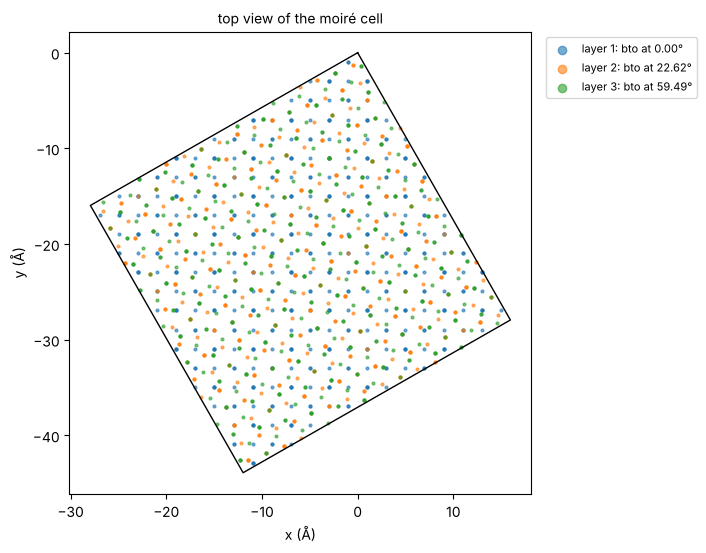

In [11]:
def plot_top_view(record, built):
    fig, ax = plt.subplots(figsize=(6, 6))
    for layer, group in built.atoms.groupby("layer"):
        ax.scatter(group["x"], group["y"], s=4, alpha=0.6,
                   label=f"layer {layer + 1}: {record.material[layer]} at {record.layer_rotations[layer]:.2f}°")
    a1, a2 = record.lattice_vectors
    outline = np.array([[0, 0], a1, a1 + a2, a2, [0, 0]])
    ax.plot(outline[:, 0], outline[:, 1], "k-", lw=1)
    ax.set_aspect("equal")
    ax.set_xlabel("x (Å)")
    ax.set_ylabel("y (Å)")
    ax.set_title("top view of the moiré cell", fontsize=10)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, markerscale=3)
    plt.show()


if chosen is not None:
    built = build_atoms(chosen, search_dirs=[REPO])
    print("atoms per layer:", built.layer_counts, "(expected", built.expected_counts, ")")
    print("composition:", built.composition)
    plot_top_view(chosen, built)

## 6. Write the structure

`INTERLAYER_GAP` is the distance between the highest atom of one layer and the lowest
possible position of the next one; `VACUUM` is added on top of the stack along c.

In [12]:
FORMATS = ["vasp", "lammps"]     # any of "vasp", "lammps"
INTERLAYER_GAP = 3.0             # Å
VACUUM = 50.0                    # Å

if chosen is not None:
    for fmt in FORMATS:
        path = write_structure(run_dir, chosen.id, fmt=fmt, interlayer_gap=INTERLAYER_GAP, vacuum=VACUUM)
        print(f"{fmt:7s} -> {path.relative_to(REPO)}")

vasp    -> runs/my_stack/structures/bto_3_22.62_36.87_015688.vasp


lammps  -> runs/my_stack/structures/bto_3_22.62_36.87_015688.data


## Worked example 1: a heterostructure (PTO / STO / PTO)

This section is independent of your input above. It runs the stack spec
`examples/pto_sto_pto_demo.yaml` and writes to `runs/pto_sto_pto_demo/`.

PbTiO₃ (PTO, a = 3.880 Å) and SrTiO₃ (STO, a = 3.913 Å) are both square, with a 0.85 %
lattice mismatch, so they are never exactly commensurate. What is different from a
homostructure:

- **Two materials:** `material` and `source_poscar` follow the stacking order; the ids
  read `pto_sto_…` and `pto_sto_pto_…`.
- **A looser tolerance in round 1** (`dtol = 9e-3`, as in
  `notebooks/Bi-layer_structure_finder.ipynb`); with the homostructure default 5e-4 the
  PTO/STO pair has no match at all.
- **Residuals compound.** The trilayer cell is a large multiple of an imperfect bilayer cell,
  so its error against the STO layer can be much larger than the error of the last step.
  The spec therefore filters on `max_layer_residual`, the error measured against every layer.

In [13]:
HETERO_SPEC = REPO / "examples" / "pto_sto_pto_demo.yaml"
print(HETERO_SPEC.read_text())

# Heterostructure PTO / STO / PTO (lattice mismatch ~0.9 %).
# Round 1 uses the bilayer notebook's tolerance (dtol 9e-3, Bi-layer_structure_finder.ipynb).
# The per-step residual stays small, but the trilayer cell is a large multiple of an
# imperfect bilayer cell, so its true error vs the STO layer grows: filter on
# max_layer_residual, not only on max_residual.
name: pto_sto_pto_demo
output_dir: runs/pto_sto_pto_demo
layers:
  - {poscar: moire_structures/PTO_STO/pto_tetra_monolayer.vasp, material: pto}
  - {poscar: moire_structures/PTO_STO/STO_centered_unit_cell_cubic_monolayer.vasp, material: sto}
  - {poscar: moire_structures/PTO_STO/pto_tetra_monolayer.vasp, material: pto}
search:
  default: {degmin: 28.0, degmax: 30.0, degstep: 0.01, dtol: 9.0e-3, nmin: -10, nmax: 10, goodangles: [90.0]}
  rounds:
    2: {degmin: 1.0, degmax: 45.0, dtol: 5.0e-4}
filters:
  max_residual: 5.0e-2
  max_layer_residual: 5.0e-2



In [14]:
hetero = run_stack_spec(HETERO_SPEC, base_dir=REPO, log=None)
hetero_dir = hetero.run_dir
print(hetero.summary())

run directory: /home/user/Multi-Layer-Moire-Generator-MLM/runs/pto_sto_pto_demo
round 1: L1 + L2 -> L1-2, carry L3
round 2: L1-2 + L3 -> L1-3
round 1: L1 + L2 -> L1-2: 1 x 1 = 1 searches -> 2 candidates, 2 passed filters (0.0 s)
round 1: carry L3 (1 candidates)
round 2: L1-2 + L3 -> L1-3: 2 x 1 = 2 searches -> 19 candidates, 6 passed filters (0.3 s)
full-stack candidates passing filters: 6


### Round 1: the PTO / STO bilayers

These are the same twists and residuals as the old bilayer notebook (`tblstopto.pkl`),
restricted to the 28–30° window used here:

In [15]:
reference = pd.read_pickle(REPO / "moire_structures" / "PTO_STO" / "tblstopto.pkl")
in_window = reference[(reference["Theta"] >= 28.0) & (reference["Theta"] < 30.0)]
old = pd.DataFrame({"twist (deg)": in_window["Theta"].round(2), "old residual (Å)": in_window["delvec"]})
new_bilayers = find(hetero_dir, n_layers=2)
new = pd.DataFrame({"twist (deg)": new_bilayers["twist"].round(2), "new residual (Å)": new_bilayers["residual"],
                    "id": new_bilayers["id"]})
old.merge(new, on="twist (deg)", how="outer").sort_values("twist (deg)").reset_index(drop=True)

,twist (deg),old residual (Å),new residual (Å),id
0,28.99,0.008259,0.008259,pto_sto_2_28.99_e2dbe7
1,29.74,0.023813,0.023813,pto_sto_2_29.74_17d636


### Round 2: the trilayers, and why `max_layer_residual` matters

Every trilayer found, passed or not. Compare two errors:
- `residual`: the error of the last step, bilayer cell + layer 3. It is small, because the
  bilayer cell is treated as perfect.
- `max layer residual`: the error of the final cell against every layer. It includes the
  STO mismatch inherited from round 1, multiplied up with the cell.

Even `cumulative_residual` (the max over all steps) underestimates it.

In [16]:
all_trilayers = [get(hetero_dir, structure_id) for structure_id in find(hetero_dir, n_layers=3)["id"]]
trilayer_table = candidate_table(all_trilayers)
trilayer_table["passed"] = [get(hetero_dir, i).worst_layer_residual <= 5e-2 for i in trilayer_table["id"]]
worst = np.array([r.worst_layer_residual for r in all_trilayers])
step = np.array([r.residual for r in all_trilayers])
cumulative = np.array([r.cumulative_residual for r in all_trilayers])
n_passed = int(trilayer_table["passed"].sum())
print(f"{len(trilayer_table)} trilayer candidates, {n_passed} pass max_layer_residual <= 0.05 Å")
print(f"max layer residual / last-step residual:   median {np.median(worst / step):.0f}x")
print(f"max layer residual / cumulative_residual:   median {np.median(worst / cumulative):.1f}x, "
      f"max {np.max(worst / cumulative):.1f}x")
trilayer_table.head(10)

19 trilayer candidates, 6 pass max_layer_residual <= 0.05 Å
max layer residual / last-step residual:   median 161x
max layer residual / cumulative_residual:   median 5.0x, max 8.1x


,id,twist 1→2 (deg),twist 2→3 (deg),cell angle (deg),|A1| (Å),|A2| (Å),atoms,residual (Å),max layer residual (Å),passed
0,pto_sto_pto_3_29.74_7.13_f78be8,29.74,7.13,90.0,44.234,44.234,2716,0.000079,0.033676,True
1,pto_sto_pto_3_29.74_29.75_fc7111,29.74,29.75,90.0,44.234,44.234,2716,0.000183,0.033676,True
2,pto_sto_pto_3_29.74_44.00_32d64b,29.74,44.00,90.0,69.940,69.940,6790,0.000250,0.053247,False
3,pto_sto_pto_3_29.74_23.39_ff5183,29.74,23.39,90.0,69.940,69.940,6790,0.000125,0.053247,False
4,pto_sto_pto_3_29.74_15.50_cfeaa7,29.74,15.50,90.0,112.774,112.774,17647,0.000532,0.085858,False
5,pto_sto_pto_3_29.74_37.64_c5eb13,29.74,37.64,90.0,112.774,112.774,17647,0.000266,0.085858,False
6,pto_sto_pto_3_28.99_7.88_b74ae7,28.99,7.88,90.0,116.709,116.709,18900,0.000208,0.018469,True
7,pto_sto_pto_3_28.99_24.14_85817b,28.99,24.14,90.0,116.709,116.709,18900,0.000208,0.018469,True
8,pto_sto_pto_3_29.74_13.49_497fcb,29.74,13.49,90.0,156.390,156.390,33936,0.001207,0.119064,False
9,pto_sto_pto_3_29.74_9.14_9b4ed1,29.74,9.14,90.0,156.390,156.390,33936,0.000190,0.119064,False


### The smallest trilayer that passes

Rebuilt from its recipe and written as VASP and LAMMPS. The atom count of every layer
(PTO, STO, PTO) matches (cell area / primitive area) × atoms per cell.

id: pto_sto_pto_3_29.74_7.13_f78be8
materials (bottom -> top): ['pto', 'sto', 'pto']
absolute layer orientations (deg): [ 0.   29.74 36.87]
per-layer residuals (Å): [0.     0.0337 0.0001]

pto_sto_pto_3_29.74_7.13_f78be8  (3 layers)  twist=7.1300  residual=7.90e-05
    pto_sto_2_29.74_17d636  (2 layers)  twist=29.7400  residual=2.38e-02
        pto_1_e344d9  (1 layer)
        sto_1_6bab52  (1 layer)
    pto_1_e344d9  (1 layer)
atoms per layer: [910, 896, 910] (expected [910, 896, 910] )
composition: {'O': 1552, 'Pb': 520, 'Sr': 256, 'Ti': 388}


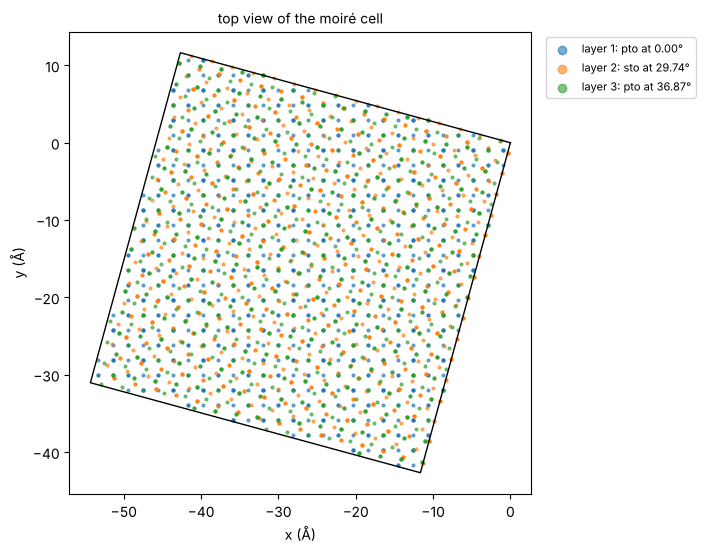

/tmp/ipykernel_6939/2480720283.py:14: RuntimeWarning: pto_sto_pto_3_29.74_7.13_f78be8: 1 check(s) FAILED: 2716 atoms, composition O1552Pb520Sr256Ti388
  problem: layer 2: closest pair 1.8144 Å differs from the primitive layer's 1.9564 Å (missing or doubled atoms?)
  min_distance: 1.7712 Å
  min_interlayer_distance: 3.9806 Å
  print(f"{fmt:7s} -> {write_structure(hetero_dir, hetero_choice.id, fmt=fmt).relative_to(REPO)}")


vasp    -> runs/pto_sto_pto_demo/structures/pto_sto_pto_3_29.74_7.13_f78be8.vasp


lammps  -> runs/pto_sto_pto_demo/structures/pto_sto_pto_3_29.74_7.13_f78be8.data


/tmp/ipykernel_6939/2480720283.py:14: RuntimeWarning: pto_sto_pto_3_29.74_7.13_f78be8: 1 check(s) FAILED: 2716 atoms, composition O1552Pb520Sr256Ti388
  problem: layer 2: closest pair 1.8144 Å differs from the primitive layer's 1.9564 Å (missing or doubled atoms?)
  min_distance: 1.7712 Å
  min_interlayer_distance: 3.9806 Å
  print(f"{fmt:7s} -> {write_structure(hetero_dir, hetero_choice.id, fmt=fmt).relative_to(REPO)}")


In [17]:
passing = candidate_table(hetero.final)
hetero_choice = get(hetero_dir, passing.loc[0, "id"])
print("id:", hetero_choice.id)
print("materials (bottom -> top):", hetero_choice.material)
print("absolute layer orientations (deg):", np.round(hetero_choice.layer_rotations, 3))
print("per-layer residuals (Å):", np.round(hetero_choice.layer_residuals, 4))
print()
print(lineage(hetero_dir, hetero_choice.id))
hetero_built = build_atoms(hetero_choice, search_dirs=[REPO])
print("atoms per layer:", hetero_built.layer_counts, "(expected", hetero_built.expected_counts, ")")
print("composition:", hetero_built.composition)
plot_top_view(hetero_choice, hetero_built)
for fmt in ["vasp", "lammps"]:
    print(f"{fmt:7s} -> {write_structure(hetero_dir, hetero_choice.id, fmt=fmt).relative_to(REPO)}")

To try your own heterostructure, put two different POSCARs in `LAYERS` (section 1),
and raise `MATCH_TOLERANCE` (advanced settings) if nothing is found.

## Worked example 2: a strained heterostructure (PTO / STO)

This section is independent of your input above. It has its own settings and writes to
`runs/example_pto_sto_*`.

PbTiO₃ (PTO, a = 3.880 Å) and SrTiO₃ (STO, a = 3.913 Å) are both square, with a lattice
mismatch of 0.85 %. Rigid layers are never exactly commensurate: the best cells are
0.008–0.03 Å off (`notebooks/Bi-layer_structure_finder.ipynb`). Here PTO is the rigid
substrate and STO may strain by up to 1 %.

In [18]:
EXAMPLE_LAYERS = [   # (POSCAR, label, max strain in %)
    ("moire_structures/PTO_STO/pto_tetra_monolayer.vasp", "pto", 0.0),                    # rigid substrate
    ("moire_structures/PTO_STO/STO_centered_unit_cell_cubic_monolayer.vasp", "sto", 1.0),  # may strain by 1 %
]
EXAMPLE_TWIST_RANGE = (5.0, 10.0)   # degrees, STO relative to PTO

example_roots = [MoireStructure.from_poscar(poscar, label, search_dirs=[REPO]) for poscar, label, _ in EXAMPLE_LAYERS]
a_pto = np.linalg.norm(example_roots[0].lattice_vectors[0])
a_sto = np.linalg.norm(example_roots[1].lattice_vectors[0])
print(f"a(PTO) = {a_pto:.4f} Å, a(STO) = {a_sto:.4f} Å, mismatch a_PTO/a_STO - 1 = {100 * (a_pto / a_sto - 1):.3f} %")


def run_example(name, limits, dtol, degstep):
    """One PTO/STO bilayer search in the example window with the given strain limits (%)."""
    params = SearchParams(degmin=EXAMPLE_TWIST_RANGE[0], degmax=EXAMPLE_TWIST_RANGE[1], degstep=degstep,
                          dtol=dtol, nmin=-10, nmax=10, goodangles=(90.0,), strain_mode="isotropic")
    example_dir = REPO / "runs" / name
    shutil.rmtree(example_dir, ignore_errors=True)
    run = build_stack(example_roots, SearchSchedule(params), Filters(), run_dir=example_dir,
                      search_dirs=[REPO], log=None, strain_limits=limits)
    return example_dir, run.final

a(PTO) = 3.8796 Å, a(STO) = 3.9127 Å, mismatch a_PTO/a_STO - 1 = -0.847 %


### Rigid vs strained

The same twist window is searched twice:
- **rigid:** both lattices fixed, with the bilayer notebook's tolerance `dtol = 9e-3`
  (needed to find anything at all);
- **strained:** STO may strain by up to 1 %, and every near-match is strained into an
  exact one.

In [19]:
rigid_dir, rigid = run_example("example_pto_sto_rigid", [0.0, 0.0], dtol=9e-3, degstep=0.01)
strained_dir, strained = run_example("example_pto_sto_strained", [0.0, 1.0], dtol=5e-4, degstep=0.1)


def by_twist(records, label):
    rows = [{"twist (deg)": round(r.twist, 2), f"{label} residual (Å)": r.residual,
             f"{label} STO strain (%)": round(r.layer_strains[1][0][0], 4)} for r in records]
    return pd.DataFrame(rows, columns=["twist (deg)", f"{label} residual (Å)", f"{label} STO strain (%)"])


comparison = by_twist(rigid, "rigid").drop(columns="rigid STO strain (%)").merge(
    by_twist(strained, "strained"), on="twist (deg)", how="outer").sort_values("twist (deg)")
low, high = EXAMPLE_TWIST_RANGE
print(f"rigid: {len(rigid)} cell(s), strained: {len(strained)} cell(s) in {low}–{high}°")
comparison.reset_index(drop=True)

rigid: 1 cell(s), strained: 13 cell(s) in 5.0–10.0°


,twist (deg),rigid residual (Å),strained residual (Å),strained STO strain (%)
0,5.60,NaN,1.222438e-11,0.6146
1,5.71,NaN,6.848117e-12,-0.3527
2,6.03,NaN,2.192583e-11,-0.8472
3,6.19,NaN,1.714866e-11,0.9503
4,6.34,NaN,4.153664e-12,-0.2370
5,6.64,NaN,1.216035e-11,0.5111
6,6.73,NaN,1.961346e-11,-0.8472
7,7.13,0.023819,1.177939e-12,-0.0756
8,7.50,NaN,1.888119e-11,0.8924
9,7.63,NaN,1.731949e-11,-0.8472


How to read this table:
- **Rigid residuals** are hundredths of an Å. **Strained residuals** are ~1e-11 Å, i.e. exact
  to machine precision.
- Strain also finds cells that rigid lattices miss completely (empty rigid columns).
- Each strained cell needs a different, small strain. Pick the one that best suits your
  simulation (cell size against strain).

### Sharing the strain

With limits 0 / 1 % only STO strains. Allowing both layers 0.5 % splits the mismatch
between them in proportion to the limits: PTO is stretched and STO compressed by about
the same amount.

In [20]:
shared_dir, shared = run_example("example_pto_sto_shared", [0.5, 0.5], dtol=5e-4, degstep=0.1)
sharing = []
for label, records in [("PTO rigid, STO ≤ 1 %", strained), ("both ≤ 0.5 %", shared)]:
    for record in records:
        if round(record.twist, 2) == 7.13:
            sharing.append({"limits": label, "twist (deg)": round(record.twist, 4),
                            "PTO strain (%)": round(record.layer_strains[0][0][0], 4),
                            "STO strain (%)": round(record.layer_strains[1][0][0], 4),
                            "residual (Å)": record.residual})
pd.DataFrame(sharing)

,limits,twist (deg),PTO strain (%),STO strain (%),residual (Å)
0,"PTO rigid, STO ≤ 1 %",7.125,0.0000,-0.0756,1.177939e-12
1,both ≤ 0.5 %,7.125,0.0378,-0.0378,1.181519e-12


### The smallest strained cell

Rebuilt from its recipe, with STO strained by the stored tensor. The atom count of every
layer matches (cell area / strained primitive area) × atoms per cell, which confirms that
the strained STO layer tiles the cell exactly.

,id,twist 1→2 (deg),cell angle (deg),|A1| (Å),|A2| (Å),atoms,residual (Å),max layer residual (Å),strain L1 (%),strain L2 (%)
0,pto_sto_2_9.46_43950b,9.462,90.0,23.598,23.598,511,6.169745e-12,6.173249e-12,0.0,0.5205
1,pto_sto_2_8.13_20873a,8.130,90.0,27.433,27.433,693,2.189149e-12,2.189211e-12,0.0,0.1594
2,pto_sto_2_7.13_914dc4,7.125,90.0,31.278,31.278,903,1.177939e-12,1.177939e-12,0.0,0.0756
3,pto_sto_2_6.34_e8b840,6.340,90.0,35.131,35.131,1141,4.153664e-12,4.153615e-12,0.0,0.2370
4,pto_sto_2_6.19_bdfda5,6.189,90.0,35.768,35.768,1169,1.714866e-11,1.715598e-11,0.0,0.9503
5,pto_sto_2_8.80_79abe7,8.797,90.0,35.768,35.768,1190,1.502155e-11,1.502425e-11,0.0,0.8472
6,pto_sto_2_5.71_d656ad,5.711,90.0,38.989,38.989,1407,6.848117e-12,6.855187e-12,0.0,0.3527
7,pto_sto_2_5.60_6d3db1,5.599,90.0,39.564,39.564,1435,1.222438e-11,1.222438e-11,0.0,0.6146
8,pto_sto_2_7.63_20990d,7.628,90.0,41.240,41.240,1582,1.731949e-11,1.731682e-11,0.0,0.8472
9,pto_sto_2_7.50_97c4dc,7.496,90.0,41.964,41.964,1610,1.888119e-11,1.888119e-11,0.0,0.8924


id: pto_sto_2_9.46_43950b
strain tensor per layer (%, own POSCAR frame):
  layer 1 (pto): [[0.0, 0.0], [0.0, 0.0]]
  layer 2 (sto): [[0.5205, 0.0], [0.0, 0.5205]]
atoms per layer: [259, 252] (expected [259, 252] )


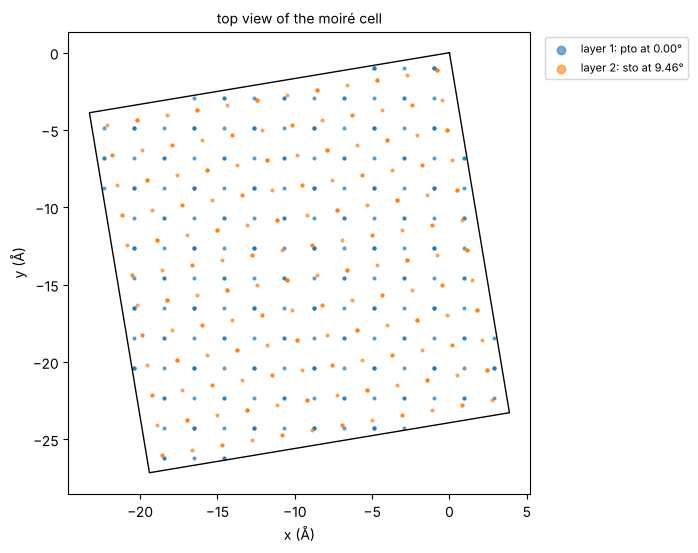

vasp    -> runs/example_pto_sto_strained/structures/pto_sto_2_9.46_43950b.vasp


lammps  -> runs/example_pto_sto_strained/structures/pto_sto_2_9.46_43950b.data


In [21]:
example_table = candidate_table(strained, with_strain=True)
display(example_table)

example = get(strained_dir, example_table.loc[0, "id"])
print("id:", example.id)
print("strain tensor per layer (%, own POSCAR frame):")
for k, tensor in enumerate(example.layer_strains, start=1):
    print(f"  layer {k} ({example.material[k - 1]}): {np.round(tensor, 4).tolist()}")
example_built = build_atoms(example, search_dirs=[REPO])
print("atoms per layer:", example_built.layer_counts, "(expected", example_built.expected_counts, ")")
plot_top_view(example, example_built)
for fmt in ["vasp", "lammps"]:
    print(f"{fmt:7s} -> {write_structure(strained_dir, example.id, fmt=fmt).relative_to(REPO)}")

The same job as a stack spec, to run from the command line:
`python -m MLM run examples/pto_sto_strained_demo.yaml` (window 1–45°).

## Coming back later

Everything is stored in `runs/<RUN_NAME>/`, so you can come back to any candidate without
searching again:

```python
from MLM.index import find, get, lineage
from MLM.build import write_structure

run_dir = "runs/my_stack"
find(run_dir, n_layers=3, max_layer_residual=1e-3)    # filter the index table
write_structure(run_dir, "<id>", fmt="vasp")         # rebuild any candidate
```

The job itself is saved as `runs/<RUN_NAME>/stack_spec.yaml`. From the repository root,
`python -m MLM run runs/<RUN_NAME>/stack_spec.yaml` repeats it from the command line.